## 1. Business Objective
The goal of this project is to build a machine learning model that predicts the selling price of cars based on their features (such as age, mileage, fuel type, brand, horsepower, etc.). You will apply Regression algorithm to understand how multiple independent variables affect the final car price.


## Step: 1 Data Gathering

In [37]:
from warnings import filterwarnings
filterwarnings('ignore')

In [38]:
import pandas as pd
df = pd.read_csv(r"D:\ML\DataSets\car_price_prediction.csv",na_values=["-","NA",""],keep_default_na=False)
df.head()

,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
0,45654403,13328,1399.0,LEXUS,RX 450,2010,Jeep,Yes,Hybrid,3.5,186005 km,6.0,Automatic,4x4,04-May,Left wheel,Silver,12
1,44731507,16621,1018.0,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3,192000 km,6.0,Tiptronic,4x4,04-May,Left wheel,Black,8
2,45774419,8467,NaN,HONDA,FIT,2006,Hatchback,No,Petrol,1.3,200000 km,4.0,Variator,Front,04-May,Right-hand drive,Black,2
3,45769185,3607,862.0,FORD,Escape,2011,Jeep,Yes,Hybrid,2.5,168966 km,4.0,Automatic,4x4,04-May,Left wheel,White,0
4,45809263,11726,446.0,HONDA,FIT,2014,Hatchback,Yes,Petrol,1.3,91901 km,4.0,Automatic,Front,04-May,Left wheel,Silver,4


In [39]:
df.shape

(19237, 18)

In [40]:
len(df)

19237

In [41]:
def fetch_km(data):
    x = data.split()
    return x[0]

In [42]:
df['Mileage'] = df['Mileage'].apply(fetch_km).astype(int)
df['Mileage']

0        186005
1        192000
2        200000
3        168966
4         91901
          ...  
19232    300000
19233    161600
19234    116365
19235     51258
19236    186923
Name: Mileage, Length: 19237, dtype: int64

In [43]:
df.dtypes

ID                    int64
Price                 int64
Levy                float64
Manufacturer            str
Model                   str
Prod. year            int64
Category                str
Leather interior        str
Fuel type               str
Engine volume           str
Mileage               int64
Cylinders           float64
Gear box type           str
Drive wheels            str
Doors                   str
Wheel                   str
Color                   str
Airbags               int64
dtype: object

In [44]:
df['Levy'] = df['Levy'].fillna(0).astype(int)

In [45]:
# Checking for duplicate values
df.duplicated().sum()

np.int64(313)

In [46]:
df = df.drop_duplicates()

In [47]:
df.duplicated().sum()

np.int64(0)

In [48]:
# Checking for Missing values.
df.isna().sum()

ID                  0
Price               0
Levy                0
Manufacturer        0
Model               0
Prod. year          0
Category            0
Leather interior    0
Fuel type           0
Engine volume       0
Mileage             0
Cylinders           0
Gear box type       0
Drive wheels        0
Doors               0
Wheel               0
Color               0
Airbags             0
dtype: int64

## EDA: Exploratory Data Analysis

In [84]:
total_revenue = df["Price"].sum()

print("Total recorded car price value:", total_revenue)

Total recorded car price value: 351748625


In [85]:
# Which year has the highest selling
year_count = df["Prod. year"].value_counts()

print("Cars by production year:")
print(year_count)

print("\nYear with the highest number of cars:")
print(year_count.idxmax())

print("Number of cars:", year_count.max())

Cars by production year:
Prod. year
2012    2131
2014    2090
2013    1913
2011    1582
2015    1527
2010    1463
2016    1449
2017     941
2008     731
2009     595
2018     491
2007     460
2005     396
2003     358
2004     354
2006     315
2019     304
2002     285
2000     277
2001     253
1999     205
1998     205
1997     151
1996     109
1995     102
2020      47
1994      41
1992      30
1993      23
1990      18
1988      12
1991      10
1989       6
1986       6
1985       5
1984       5
1987       5
1953       4
1983       3
1939       3
1977       2
1964       2
1978       2
1965       2
1980       2
1974       1
1943       1
1976       1
1957       1
1968       1
1947       1
1982       1
1981       1
1973       1
Name: count, dtype: int64

Year with the highest number of cars:
2012
Number of cars: 2131


In [86]:
# Which car model is listed the most
model_count = df["Model"].value_counts()

print("Top 10 most frequently listed models:")
print(model_count.head(10))

print("\nMost frequently listed model:")
print(model_count.idxmax())

print("Number of records:", model_count.max())

Top 10 most frequently listed models:
Model
Prius       1069
Sonata      1067
Camry        929
Elantra      910
E 350        534
Santa FE     527
FIT          444
H1           435
Tucson       426
X5           351
Name: count, dtype: int64

Most frequently listed model:
Prius
Number of records: 1069


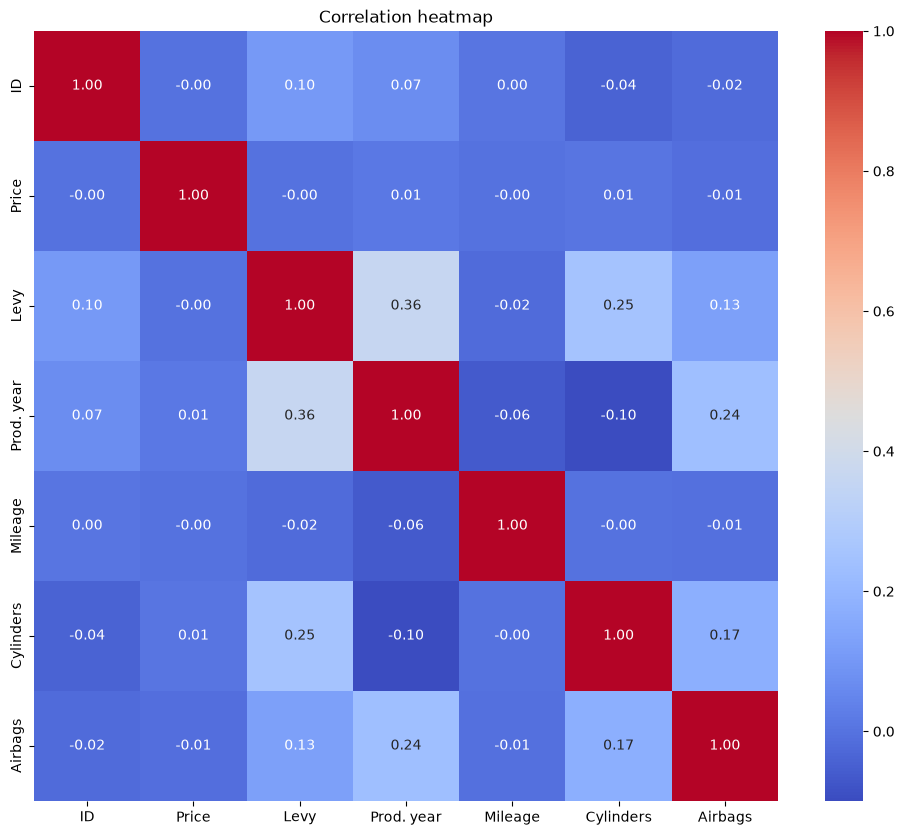

In [61]:
## Correlation 

import seaborn as sns
import matplotlib.pyplot as plt

corr = df.select_dtypes(include="number").corr()
plt.figure(figsize=(12,10))
sns.heatmap(corr,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation heatmap")
plt.show()

## Analysis: 
- There is no correlation between independent and target feature

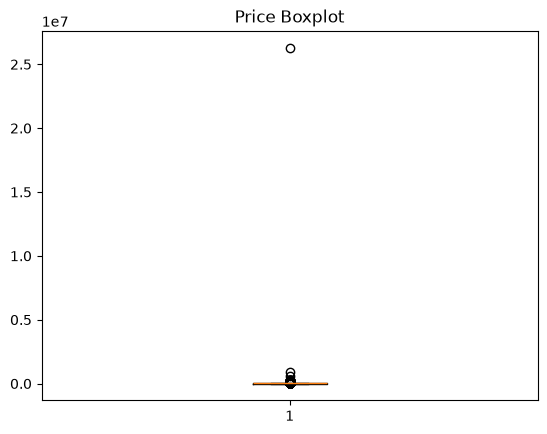

In [62]:
## Box Plot
import matplotlib.pyplot as plt

plt.boxplot(df["Price"])
plt.title("Price Boxplot")
plt.show()

## Analysis: 
- Several outliers are present

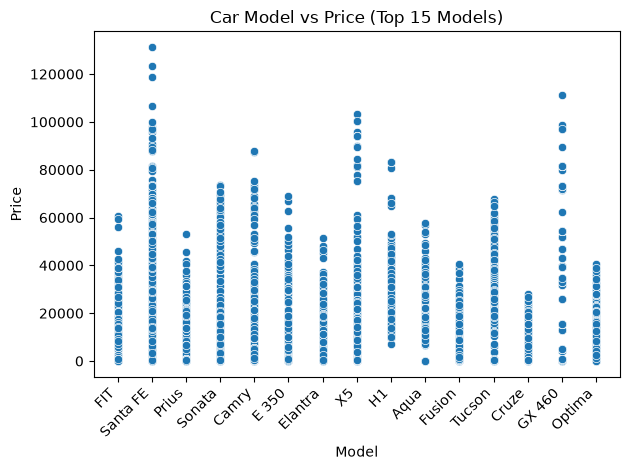

In [63]:
## Scatter plot
import seaborn as sns
import matplotlib.pyplot as plt

top_models = df["Model"].value_counts().head(15).index

data = df[df["Model"].isin(top_models)]

sns.scatterplot(data=data, x="Model", y="Price")

plt.xticks(rotation=45, ha="right")
plt.title("Car Model vs Price (Top 15 Models)")
plt.tight_layout()
plt.show()


## Analysis: 
- Highest price of car model is above 120000.
- Highest price model is Santa FE car. 

In [49]:
# Checking for Outliers 
cat = list(df.select_dtypes(include='object').columns)
con = list(df.select_dtypes(include='number').columns)

In [50]:
import numpy as np 
out_summary = {}
for col in con: 

    q1 = np.percentile(df[col], 25)
    q3 = np.percentile(df[col], 75)

    iqr = q3 - q1

    minimum = q1 - 1.5 * iqr
    maximum = q3 + 1.5 * iqr

    lower_out = df[col] < minimum
    upper_out = df[col] > maximum

    outliers = df[lower_out | upper_out]

    print("===============================")
    print(f"Outliers less than minimum: {df[lower_out]}")
    print(f"Outliers more than maximum: {df[upper_out]}")
    print(f"Number of Outliers for {col}: {len(outliers)}")
    out_summary[col] = {
        "lower": minimum,
        "upper": maximum,
        "outlier_count": len(outliers),
        "outlier_pct": round(len(outliers)/len(df) * 100, 2)
        }
    out_report = pd.DataFrame(out_summary).T
    out_report

Outliers less than minimum:              ID  Price  Levy   Manufacturer        Model  Prod. year  \
1      44731507  16621  1018      CHEVROLET      Equinox        2011   
15     45465200    549  1079         TOYOTA          CHR        2018   
21     45168471  20698   586         TOYOTA        Prius        2012   
30     44944581  15681  1288  MERCEDES-BENZ         Vito        2007   
36     45369569  51746  1077         TOYOTA  CHR Limited        2019   
...         ...    ...   ...            ...          ...         ...   
19176  45511664  14113   531        HYUNDAI     Veloster        2012   
19192  45172859  14113     0          SCION           xD        2010   
19208  45433278  34811   779         TOYOTA        RAV 4        2013   
19223  44571028   8781     0          DODGE      Caliber        2008   
19229  39977395     50     0         TOYOTA        Prius        2008   

          Category Leather interior       Fuel type Engine volume  Mileage  \
1             Jeep           

## Analysis from outlier 
- Outliers are present in the dataset. 
- Number of Outliers in Cylinders: 4765.
- Number of Outliers in Mileage: 673.
- Number of Outliers in Prod. Year: 962.
- Number of Outliers in Levy: 160.
- Number of Outliers in Price: 1055. 

In [51]:
# Outlier Handling
def handle_outlier(df,col,outlier_percent,mini,maxi):
    lower_index = list(df[df[col]<mini].index)
    upper_index = list(df[df[col]>maxi].index)
    all_ = lower_index + upper_index

    df_new = df.copy()
    if outlier_percent<10:
        df_new = df.drop(index=all_)
    else:
        df_new[col] = df[col].clip(mini,maxi)
    return df_new

In [52]:
df2 = df.copy()
for i in con:
    out_perc = out_report.loc[i,'outlier_pct']
    mini = out_report.loc[i,'lower']
    maxi = out_report.loc[i,'upper']
    df2 = handle_outlier(df2,i,out_perc,mini,maxi)
df2

,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
0,4.565440e+07,13328,1399,LEXUS,RX 450,2010,Jeep,Yes,Hybrid,3.5,186005,4.0,Automatic,4x4,04-May,Left wheel,Silver,12
1,4.553491e+07,16621,1018,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3,192000,4.0,Tiptronic,4x4,04-May,Left wheel,Black,8
2,4.577442e+07,8467,0,HONDA,FIT,2006,Hatchback,No,Petrol,1.3,200000,4.0,Variator,Front,04-May,Right-hand drive,Black,2
3,4.576918e+07,3607,862,FORD,Escape,2011,Jeep,Yes,Hybrid,2.5,168966,4.0,Automatic,4x4,04-May,Left wheel,White,0
4,4.580926e+07,11726,446,HONDA,FIT,2014,Hatchback,Yes,Petrol,1.3,91901,4.0,Automatic,Front,04-May,Left wheel,Silver,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19231,4.577231e+07,5802,1055,MERCEDES-BENZ,E 350,2013,Sedan,Yes,Diesel,3.5,107800,4.0,Automatic,Rear,04-May,Left wheel,Grey,12
19233,4.577886e+07,15681,831,HYUNDAI,Sonata,2011,Sedan,Yes,Petrol,2.4,161600,4.0,Tiptronic,Front,04-May,Left wheel,Red,8
19234,4.580500e+07,26108,836,HYUNDAI,Tucson,2010,Jeep,Yes,Diesel,2,116365,4.0,Automatic,Front,04-May,Left wheel,Grey,4
19235,4.579353e+07,5331,1288,CHEVROLET,Captiva,2007,Jeep,Yes,Diesel,2,51258,4.0,Automatic,Front,04-May,Left wheel,Black,4


## We can check the skewedness of data using df[continuous_col_name].skew()

    It provides a numeric range.

    -0.5 to 0.5   → nearly normal
    0.5 to 1     → moderate skewed
    > 1          → highly skewed

In [53]:
# Checking for Skeweed Data
df1_copy = df2.copy()

In [54]:
df1_copy[con].skew()

ID           -1.185429
Price         0.759230
Levy          0.344914
Prod. year   -0.823496
Mileage       0.466647
Cylinders     0.000000
Airbags      -0.001687
dtype: float64

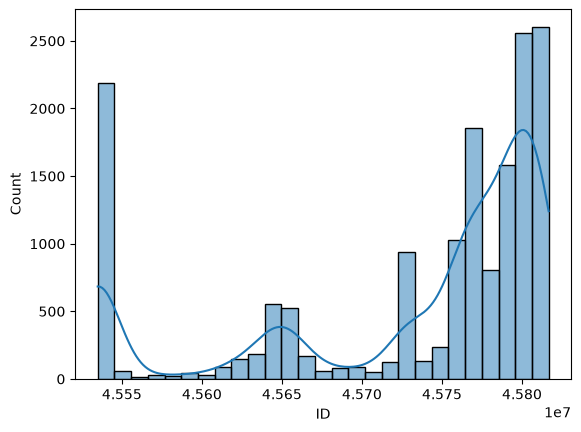

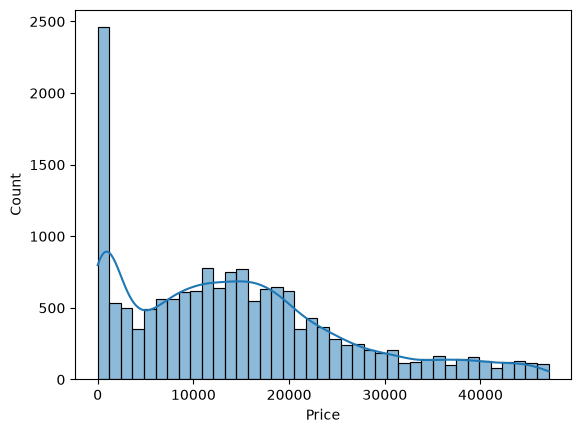

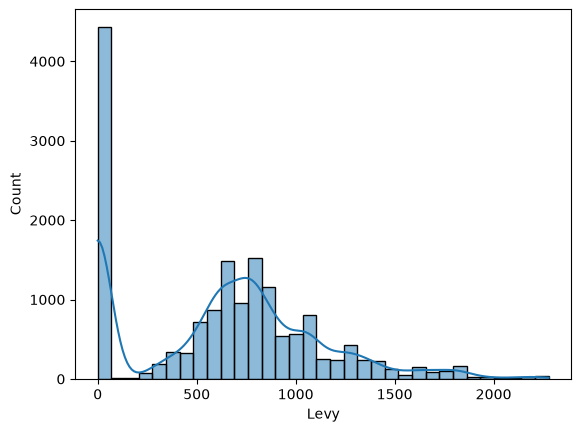

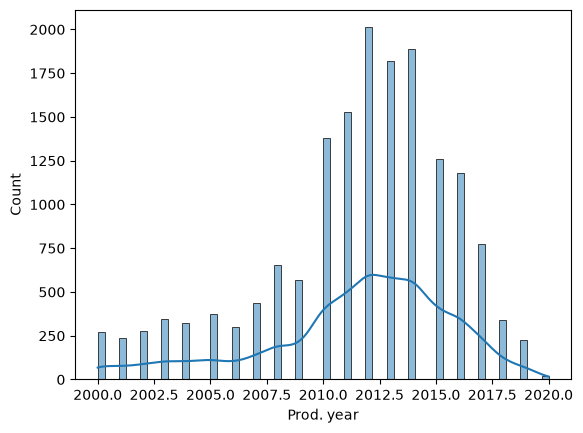

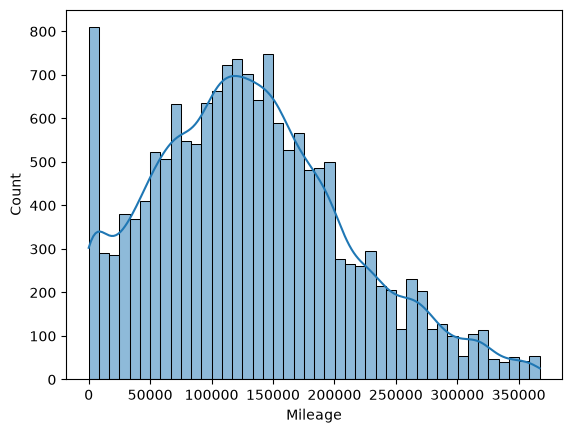

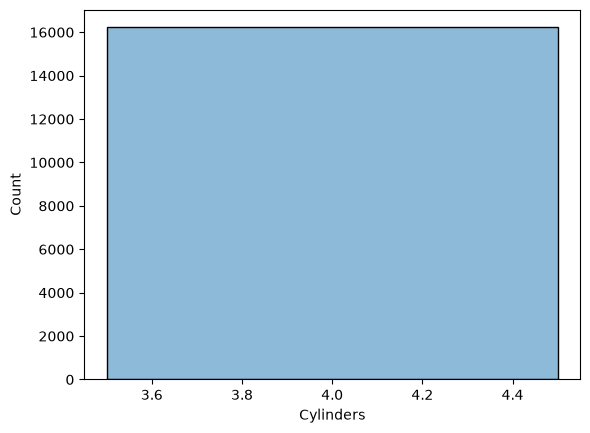

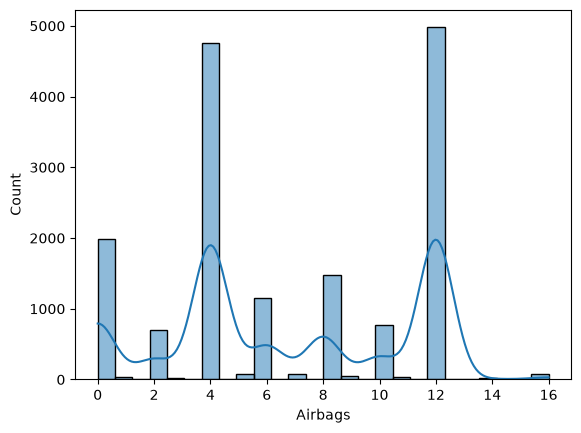

In [55]:
import seaborn as sns
import matplotlib.pyplot as plt
for i in con:
    sns.histplot(df1_copy[i],kde=True)
    plt.show()

In [59]:
# Descriptive Analysis
df2.describe()

,ID,Price,Levy,Prod. year,Mileage,Cylinders,Airbags
count,1.621800e+04,16218.000000,16218.000000,16218.000000,16218.000000,16218.0,16218.000000
mean,4.573176e+07,14705.896411,628.783019,2011.521458,131979.496670,4.0,6.783327
std,9.391197e+04,11583.914771,487.604326,4.204191,79275.108199,0.0,4.305190
min,4.553491e+07,1.000000,0.000000,2000.000000,0.000000,4.0,0.000000
25%,4.566923e+07,5331.000000,0.000000,2010.000000,73249.500000,4.0,4.000000
50%,4.577120e+07,13328.000000,645.000000,2012.000000,126000.000000,4.0,6.000000
75%,4.580160e+07,21012.000000,900.000000,2014.000000,180000.000000,4.0,12.000000
max,4.581665e+07,47120.000000,2278.000000,2020.000000,367053.000000,4.0,16.000000


## Step: 3 Model Development

###  Split dataset into train and test sets.

In [64]:
X = df2.drop(columns=['ID',"Price","Gear box type","Drive wheels","Doors","Wheel"])
Y = df2[['Price']]

In [65]:
for i in ['Manufacturer','Model','Category','Leather interior','Fuel type','Engine volume','Color']:
    print(i,X[i].unique(),sep='\n')

Manufacturer
<StringArray>
[        'LEXUS',     'CHEVROLET',         'HONDA',          'FORD',
       'HYUNDAI',        'TOYOTA', 'MERCEDES-BENZ',       'PORSCHE',
           'BMW',          'JEEP',    'VOLKSWAGEN',          'AUDI',
       'RENAULT',        'NISSAN',        'SUBARU',        'DAEWOO',
           'KIA',    'MITSUBISHI',     'SSANGYONG',         'MAZDA',
           'GMC',          'FIAT',      'INFINITI',    'ALFA ROMEO',
        'SUZUKI',          'OPEL',         'ACURA',       'CITROEN',
          'MINI',         'DODGE',      'CHRYSLER',         'ISUZU',
           'VAZ',        'JAGUAR',         'SKODA',       'LINCOLN',
         'BUICK',      'DAIHATSU',      'CADILLAC',       'PEUGEOT',
         'VOLVO',          'სხვა',         'HAVAL',    'LAND ROVER',
         'SCION',       'MERCURY',          'SEAT',        'LANCIA',
      'MASERATI',        'HUMMER',          'SAAB',           'GAZ',
           'UAZ',       'PONTIAC',        'SATURN',     'GREATWALL']
Length:

### Manufacturer and Engine volume has too many unique features. will apply Label encoding to it

In [66]:
cat = list(X.select_dtypes(include='object').columns) 
con = list(X.select_dtypes(include='number').columns)
print(cat)
print(con)

['Manufacturer', 'Model', 'Category', 'Leather interior', 'Fuel type', 'Engine volume', 'Color']
['Levy', 'Prod. year', 'Mileage', 'Cylinders', 'Airbags']


In [67]:
cat_onehot = ['Model', 'Category', 'Leather interior', 'Fuel type', 'Color']
cat_label = ['Manufacturer','Engine volume']

## Data Cleaning and Preprocessing

In [68]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder,LabelEncoder
from sklearn.compose import ColumnTransformer

num_pipe = make_pipeline(SimpleImputer(strategy='median'),
                         StandardScaler())

cat_pipe = make_pipeline(SimpleImputer(strategy='most_frequent'),
                         OneHotEncoder(handle_unknown='ignore',sparse_output=False))

pre = ColumnTransformer([('cat',cat_pipe,cat_onehot),
                         ('con',num_pipe,con)]).set_output(transform='pandas')

from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest = train_test_split(X,Y,random_state=21,train_size=0.75)

pre.fit(xtrain)

xtrain_pre = pre.transform(xtrain)
xtest_pre = pre.transform(xtest)

# Apply LabelEncoder separately
encoders = {}

for col in cat_label:
    # Impute missing values using training data's most frequent value
    most_frequent = xtrain[col].mode().iloc[0]

    train_col = xtrain[col].fillna(most_frequent).astype(str)
    test_col = xtest[col].fillna(most_frequent).astype(str)

    le = LabelEncoder()
    xtrain_pre[col] = le.fit_transform(train_col)

    # Handle categories in test data that weren't present in training
    mapping = {v: i for i, v in enumerate(le.classes_)}
    xtest_pre[col] = test_col.map(mapping).fillna(-1).astype(int)

    encoders[col] = le

In [69]:
xtrain_pre.columns

Index(['cat__Model_09-Mar', 'cat__Model_100', 'cat__Model_100 NX',
       'cat__Model_1000', 'cat__Model_114', 'cat__Model_116', 'cat__Model_118',
       'cat__Model_118 M-sport LCI', 'cat__Model_120', 'cat__Model_128',
       ...
       'cat__Color_Sky blue', 'cat__Color_White', 'cat__Color_Yellow',
       'con__Levy', 'con__Prod. year', 'con__Mileage', 'con__Cylinders',
       'con__Airbags', 'Manufacturer', 'Engine volume'],
      dtype='str', length=1182)

In [97]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(xtrain_pre, ytrain)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1182)","[[-14067.55, 994.01,-13396.14,..., -1114.29, 163.11, -22.35]]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1182,)","['cat__Model_09-Mar','cat__Model_100','cat__Model_100 NX',..., 'con__Airbags','Manufacturer','Engine volume']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[16551.75]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1182
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1176)


In [98]:
model.coef_

array([[-14067.54593803,    994.00716842, -13396.13974772, ...,
         -1114.28523674,    163.11250132,    -22.35132407]],
      shape=(1, 1182))

In [99]:
model.intercept_

array([16551.74915399])

In [100]:
ypred_test = model.predict(xtest_pre)
ypred_test[:5]

array([[15187.96872862],
       [ 5594.51955081],
       [15475.48247856],
       [25541.60265613],
       [14544.53847214]])

In [101]:
ytest.head()

,Price
15569,2998
6422,4077
85,19121
5722,18240
15920,2038


In [102]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

mse = mean_squared_error(ytest, ypred_test)
mae = mean_absolute_error(ytest, ypred_test)
rmse = mse**0.5
r2 = r2_score(ytest, ypred_test)

print(f"Testing Scores")
print(f"MSE: {mse}")
print(f"MAE: {mae}")
print(f"RMSE: {rmse}")
print(f"R2 score-Coefficient of Determination:{r2*100:.2f}")

Testing Scores
MSE: 87587581.57612461
MAE: 7010.466619108788
RMSE: 9358.823728232337
R2 score-Coefficient of Determination:33.55


## Since R2 score is very low we will move forward with more algorithm evaluation.

## Step: 4 Algorithm Evaluation

In [70]:
import re

# Replace [, ], and < with an underscore
xtrain_pre.columns = [re.sub(r'[\[\]<]', '_', str(col)) for col in xtrain_pre.columns]
xtest_pre.columns = [re.sub(r'[\[\]<]', '_', str(col)) for col in xtest_pre.columns]

In [71]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor

In [72]:
from xgboost import XGBRegressor

In [73]:
dct = {
    "Linear":LinearRegression(),
    "Decision":DecisionTreeRegressor(),
    "Random":RandomForestRegressor(),
    "Gradient":GradientBoostingRegressor(),
    "XGB":XGBRegressor()
}

In [74]:
r2 = []
from sklearn.metrics import r2_score
for model in dct.values():
    model.fit(xtrain_pre,ytrain['Price'])
    preds = model.predict(xtest_pre)
    score = r2_score(ytest,preds)
    r2.append(score)

In [75]:
r2

[0.33553224722046826,
 0.496347806557928,
 0.7251353777562775,
 0.5595267919614385,
 0.6732509136199951]

In [76]:
model_results = pd.DataFrame(list(zip(list(dct.keys()),r2)),columns=["Model Name","R2 Scores"]).sort_values(by="R2 Scores",ascending=False)
model_results

,Model Name,R2 Scores
2,Random,0.725135
4,XGB,0.673251
3,Gradient,0.559527
1,Decision,0.496348
0,Linear,0.335532


## RandomForestRegressor giving highest r2 score so we can proceed with RandomForestRegressor 

### Hyperparameter Tuning

In [77]:
params ={'n_estimators':[50,100,125,150],
        'max_depth':[10,15,20,25]}

In [78]:
from sklearn.model_selection import RandomizedSearchCV
rscv = RandomizedSearchCV(estimator=RandomForestRegressor(),param_distributions=params,cv=3,scoring='r2')
rscv.fit(xtrain_pre,ytrain['Price'])

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestRegressor()
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [10, 15, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use `

In [79]:
rscv.best_params_

{'n_estimators': 150, 'max_depth': 25}

In [80]:
rscv.best_score_

np.float64(0.6965486978242272)

In [ ]:
import joblib
joblib.dump(model_results,"Model.joblib")
joblib.dump(pre,"pipeline.joblib")

['pipeline.joblib']